<a href="https://colab.research.google.com/github/chimmy003/COU07506_WEEK2_240242496495/blob/main/COU07506_Week03_240242496495.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

WEEK 3 LABS WORK    
NAME: CHIMILO CHIMILO LABAN   
REG NO: 240242496495    
CLASS: BENG24COE-3


Task 3.1 — Convolution from the definition
Objective: Write our own convolution function and compare its output with NumPy's built-in np.convolve() function.


In [27]:
import numpy as np

def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]

    return y


# Input sequences
x = [1, 2, 3, 1]
h = [1, 1, 1]

# Our convolution function
result1 = conv(x, h)

# NumPy built-in convolution
result2 = np.convolve(x, h)

print("Our convolution:", result1)
print("NumPy convolution:", result2)

Our convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]


In [28]:
import time

# Generate two random sequences
rng = np.random.default_rng(0)

x = rng.standard_normal(2000)
h = rng.standard_normal(2000)

# Measure time for our convolution
start = time.perf_counter()
y1 = conv(x, h)
time1 = time.perf_counter() - start

# Measure time for NumPy convolution
start = time.perf_counter()
y2 = np.convolve(x, h)
time2 = time.perf_counter() - start

print("Our convolution time:", time1, "seconds")
print("NumPy convolution time:", time2, "seconds")
print("Outputs match:", np.allclose(y1, y2))

Our convolution time: 3.234465569999884 seconds
NumPy convolution time: 0.0010149830000045768 seconds
Outputs match: True


Task 3.2 Smoothing a Noisy Signal by Convolution
Objective: To understand how moving-average filters reduce noise in a signal.

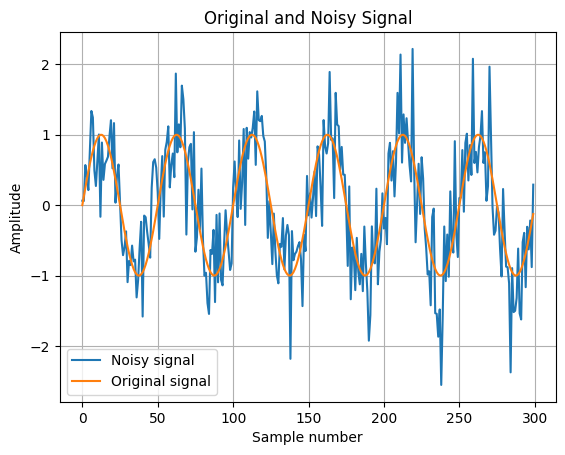

In [29]:
import matplotlib.pyplot as plt

# Generate the signal
n = np.arange(300)

# Original sine wave
clean_signal = np.sin(2 * np.pi * n / 50)

# Generate Gaussian noise
rng = np.random.default_rng(0)
noise = 0.5 * rng.standard_normal(300)

# Add noise to the original signal
x = clean_signal + noise

# Plot the noisy signal
plt.plot(n, x, label="Noisy signal")
plt.plot(n, clean_signal, label="Original signal")
plt.xlabel("Sample number")
plt.ylabel("Amplitude")
plt.title("Original and Noisy Signal")
plt.legend()
plt.grid()
plt.show()

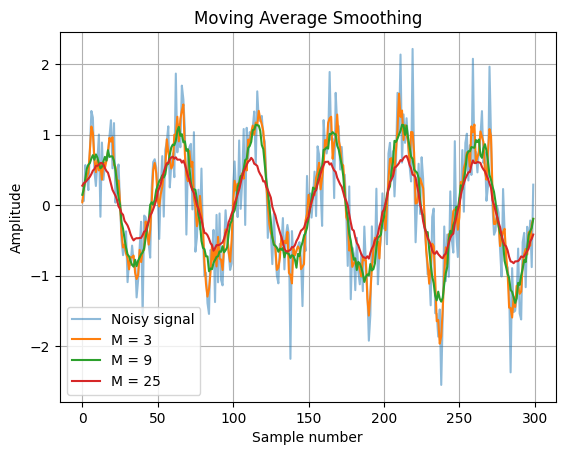

In [30]:

# Moving-average filter sizes
M_values = [3, 9, 25]

# Plot original noisy signal
plt.plot(n, x, label="Noisy signal", alpha=0.5)

# Apply each moving-average filter
for M in M_values:
    h = np.ones(M) / M
    smoothed = np.convolve(x, h, mode="same")

    plt.plot(n, smoothed, label=f"M = {M}")

plt.xlabel("Sample number")
plt.ylabel("Amplitude")
plt.title("Moving Average Smoothing")
plt.legend()
plt.grid()
plt.show()


Task 3.3 — Testing Linearity and Time-Invariance Numerically
Objective: To test whether different systems satisfy the properties of linearity and time-invariance.


In [31]:

# Generate two random input signals
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

# Constants
a = 2.0
b = -3.0

# Define three systems
systems = {
    "x^2": lambda x: x**2,

    "n x(n)": lambda x: np.arange(len(x)) * x,

    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

# Test each system
for name, T in systems.items():

    # Test linearity
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Delay the input by 5 samples
    xd = np.concatenate([np.zeros(5), x1])[:50]

    # Delay the original output by 5 samples
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    # Test time-invariance
    time_invariant = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear} time-invariant={time_invariant}")


x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


Task 3.4 — Finding a Hidden Delay with Cross-Correlation
Objective: To use cross-correlation to estimate the time delay between two signals.

In [32]:

# Generate a random transmitted signal
rng = np.random.default_rng(1)

fs = 1000  # Sampling frequency in Hz
x = rng.standard_normal(500)

# Introduce a delay of 37 samples
true_delay = 37

# Create the received signal and add noise
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + 0.5*rng.standard_normal(500)

print("Original signal samples:", len(x))
print("Received signal samples:", len(y))
print("Actual delay:", true_delay, "samples")


Original signal samples: 500
Received signal samples: 500
Actual delay: 37 samples


Estimated delay: 37 samples


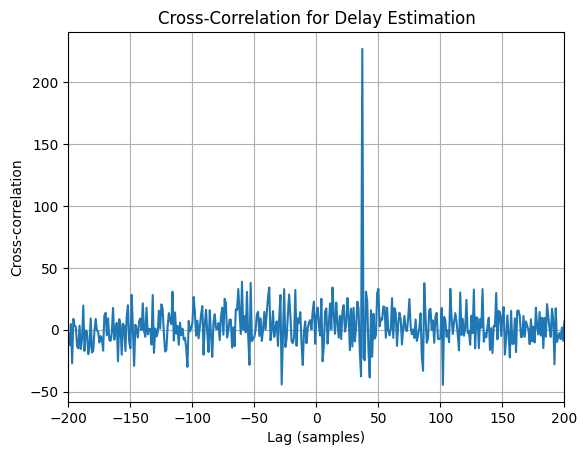

In [33]:
from scipy import signal

# Calculate cross-correlation
r = signal.correlate(y, x, mode="full")

# Generate lag values
lags = signal.correlation_lags(len(y), len(x), mode="full")

# Find the lag where correlation is maximum
estimated_delay = lags[np.argmax(r)]

print("Estimated delay:", estimated_delay, "samples")

# Plot cross-correlation
plt.plot(lags, r)
plt.xlim(-200, 200)
plt.xlabel("Lag (samples)")
plt.ylabel("Cross-correlation")
plt.title("Cross-Correlation for Delay Estimation")
plt.grid()
plt.show()

In [34]:

# Test different noise levels
noise_levels = [0.5, 1, 2, 4]

for noise_std in noise_levels:

    rng = np.random.default_rng(1)

    noise = noise_std * rng.standard_normal(500)

    y_test = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + noise

    r_test = signal.correlate(y_test, x, mode="full")
    lags_test = signal.correlation_lags(len(y_test), len(x), mode="full")

    delay = lags_test[np.argmax(r_test)]

    print("Noise standard deviation:", noise_std,
          "| Estimated delay:", delay, "samples")


Noise standard deviation: 0.5 | Estimated delay: 37 samples
Noise standard deviation: 1 | Estimated delay: 0 samples
Noise standard deviation: 2 | Estimated delay: 0 samples
Noise standard deviation: 4 | Estimated delay: 0 samples


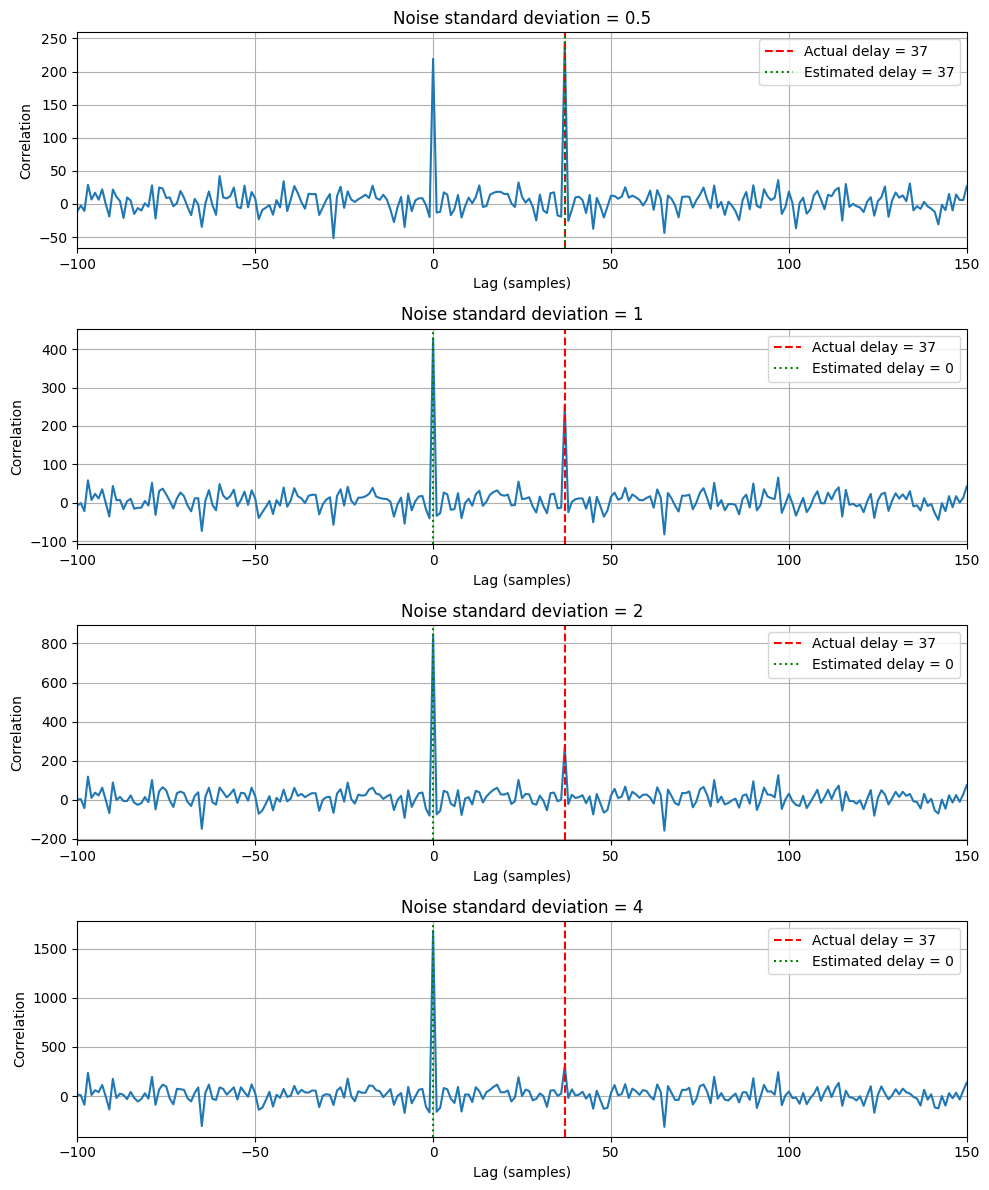

In [35]:

# Different noise levels
noise_levels = [0.5, 1, 2, 4]

# Create four graphs
fig, axes = plt.subplots(4, 1, figsize=(10, 12))

for i, noise_std in enumerate(noise_levels):

    # Generate noise
    rng = np.random.default_rng(1)
    noise = noise_std * rng.standard_normal(500)

    # Create received signal
    y_test = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + noise

    # Calculate cross-correlation
    r_test = signal.correlate(y_test, x, mode="full")
    lags_test = signal.correlation_lags(len(y_test), len(x), mode="full")

    # Estimate delay
    estimated_delay = lags_test[np.argmax(r_test)]

    # Plot correlation
    axes[i].plot(lags_test, r_test)
    axes[i].axvline(true_delay, color="red", linestyle="--",
                    label="Actual delay = 37")
    axes[i].axvline(estimated_delay, color="green", linestyle=":",
                    label=f"Estimated delay = {estimated_delay}")

    axes[i].set_xlim(-100, 150)
    axes[i].set_title(f"Noise standard deviation = {noise_std}")
    axes[i].set_xlabel("Lag (samples)")
    axes[i].set_ylabel("Correlation")
    axes[i].legend()
    axes[i].grid()

plt.tight_layout()
plt.show()


```markdown
## Task 3.5 — Difference equation

For the system described by the difference equation:
$$y(n) - \frac{3}{4}y(n-1) + \frac{1}{8}y(n-2) = x(n) + x(n-1)$$

We will:
1. Compute the impulse response $h(n)$ for $0 \le n \le 9$ by direct recursion.
2. Compute $h(n)$ using `scipy.signal.lfilter`.
3. Compare the numerical results with the analytical closed-form solution: $h(n) = 6(0.5)^n - 5(0.25)^n$.
4. Compute the step response using `lfilter`, find its final steady-state value, and compare it with the theoretical DC gain $H(1) = \frac{\sum b}{\sum a}$.
```

In [36]:
import numpy as np
from scipy import signal

# --- 1. Compute h(n) by Direct Recursion ---
N = 10
h_rec = np.zeros(N)

# Impulse input x(n) = delta(n)
def x_impulse(n):
    return 1.0 if n == 0 or n == 1 else 0.0  # since RHS is x(n) + x(n-1)

# Direct recursion: y(n) = 0.75 * y(n-1) - 0.125 * y(n-2) + x(n) + x(n-1)
for n in range(N):
    y_prev1 = h_rec[n-1] if n - 1 >= 0 else 0.0
    y_prev2 = h_rec[n-2] if n - 2 >= 0 else 0.0

    # x_term = x(n) + x(n-1)
    x_n = 1.0 if n == 0 else 0.0
    x_n_minus_1 = 1.0 if n == 1 else 0.0

    h_rec[n] = 0.75 * y_prev1 - 0.125 * y_prev2 + x_n + x_n_minus_1

# --- 2. Compute h(n) with scipy.signal.lfilter ---
b = [1, 1]              # Coefficients of x
a_coeff = [1, -0.75, 0.125] # Coefficients of y

# Create unit impulse sequence delta(n)
impulse = np.zeros(N)
impulse[0] = 1.0

h_filter = signal.lfilter(b, a_coeff, impulse)

# --- 3. Compare with Closed-Form Solution ---
n_vals = np.arange(N)
h_closed = 6 * (0.5)**n_vals - 5 * (0.25)**n_vals

# --- Print Impulse Response Comparisons ---
print("n   | h_recursion | h_lfilter   | h_closed_form")
print("-" * 48)
for n in range(N):
    print(f"{n:3d} | {h_rec[n]:11.6f} | {h_filter[n]:11.6f} | {h_closed[n]:11.6f}")

print("\nAll impulse responses match:", np.allclose(h_rec, h_filter) and np.allclose(h_filter, h_closed))

# --- 4. Step Response and Final Value ---
# Create unit step sequence u(n) for a longer range to observe steady state
N_step = 100
step_input = np.ones(N_step)

step_response = signal.lfilter(b, a_coeff, step_input)
final_value_numerical = step_response[-1]

# Theoretical final value H(1) = sum(b) / sum(a)
theoretical_dc_gain = sum(b) / sum(a_coeff)

print("\n--- Step Response Verification ---")
print(f"Numerical final value (at n=99): {final_value_numerical:.6f}")
print(f"Theoretical final value H(1):      {theoretical_dc_gain:.6f}")
print("Final values match:", np.isclose(final_value_numerical, theoretical_dc_gain))

n   | h_recursion | h_lfilter   | h_closed_form
------------------------------------------------
  0 |    1.000000 |    1.000000 |    1.000000
  1 |    1.750000 |    1.750000 |    1.750000
  2 |    1.187500 |    1.187500 |    1.187500
  3 |    0.671875 |    0.671875 |    0.671875
  4 |    0.355469 |    0.355469 |    0.355469
  5 |    0.182617 |    0.182617 |    0.182617
  6 |    0.092529 |    0.092529 |    0.092529
  7 |    0.046570 |    0.046570 |    0.046570
  8 |    0.023361 |    0.023361 |    0.023361
  9 |    0.011700 |    0.011700 |    0.011700

All impulse responses match: True

--- Step Response Verification ---
Numerical final value (at n=99): 5.333333
Theoretical final value H(1):      5.333333
Final values match: True


General Conclusion
Through this laboratory, I was able to explore and understand how digital signal processing techniques work in practice. I used Python to perform convolution, smooth noisy signals, test system properties, estimate signal delays using cross-correlation, and solve difference equations.

The practical activities helped me understand how changing filter sizes affects signal quality, how noise influences delay estimation, and how different systems behave in terms of linearity and time-invariance.

Overall, this laboratory was an interactive learning experience because I was able to write code, change parameters, observe graphs, compare results, and understand how digital signals behave.